Zebranie danych z API sejmowgo
Matryca poseł x liczba głosowań

In [23]:
import requests
import pandas as pd
import networkx as nx
from itertools import combinations 
import numpy as np

In [24]:
BASE = 'https://api.sejm.gov.pl/sejm'
#obecna kadencja
TERM = 10


#lista posiedzeń
def get_sittings():
    r = requests.get(f'{base}/term{TERM}/votings')
    return r.json()


In [25]:
#głosowania z danego posiedzenia
def get_votes_from_sitting(sitting_num):
    r = requests.get(f"{BASE}/term{TERM}/votings/{sitting_num}")
    votings = r.json()
    
    votes = []
    for v in votings:
        voting_num = v["votingNumber"]
        detail = requests.get(
            f"{BASE}/term{TERM}/votings/{sitting_num}/{voting_num}"
        ).json()
        
        for vote in detail.get("votes", []):
            votes.append({
                "posel": vote["MP"],           
                "nazwisko": vote["lastName"],
                "klub": vote["club"],
                "glosowanie_id": f"{sitting_num}_{voting_num}",
                "wynik": vote["vote"]          
            })
    return votes

In [26]:
#test, dane z kilku posiedzeń
#posiedzneia ze srodka kadencji, bardziej zrozncowane, faktyczne glosowania podparte interesami i ideologia, a nie tylko administracja
all_votes = []
for sitting in range(20,35):
    print(f'Pobieranie dane z posiedzenia {sitting}')
    all_votes.extend(get_votes_from_sitting(sitting))

df = pd.DataFrame(all_votes)
df.to_csv('glosowania_raw.csv', index=False)

Pobieranie dane z posiedzenia 20
Pobieranie dane z posiedzenia 21
Pobieranie dane z posiedzenia 22
Pobieranie dane z posiedzenia 23
Pobieranie dane z posiedzenia 24
Pobieranie dane z posiedzenia 25
Pobieranie dane z posiedzenia 26
Pobieranie dane z posiedzenia 27
Pobieranie dane z posiedzenia 28
Pobieranie dane z posiedzenia 29
Pobieranie dane z posiedzenia 30
Pobieranie dane z posiedzenia 31
Pobieranie dane z posiedzenia 32
Pobieranie dane z posiedzenia 33
Pobieranie dane z posiedzenia 34


In [27]:
df = pd.DataFrame(all_votes)
df.to_csv('glosowania_raw.csv', index=False)

In [28]:
print(df.shape)
print(df["glosowanie_id"].nunique())   # ile unikalnych głosowań
print(df["posel"].nunique())           # ilu posłów
print(df["wynik"].value_counts())      # rozkład YES/NO/ABSTAIN
print(df["klub"].value_counts())       # ile posłów per klub

(455823, 5)
991
460
wynik
YES           224559
NO            181282
ABSENT         28342
ABSTAIN        16997
PRESENT         4218
VOTE_VALID       425
Name: count, dtype: int64
klub
PiS              188290
KO               155550
PSL-TD            31712
Polska2050-TD     31712
Lewica            20996
Konfederacja      17370
Razem              4770
Republikanie       3948
niez.              1459
Kukiz15              16
Name: count, dtype: int64


In [29]:
klub_mapping = {
    'Polska2050' : 'Polska2050-TD',
    'PSL' : 'PSL-TD',
    'Nowa_Lewica' : 'Lewica'
}
df['klub'] = df['klub'].replace(klub_mapping)
print(df['klub'].value_counts())

klub
PiS              188290
KO               155550
PSL-TD            31712
Polska2050-TD     31712
Lewica            20996
Konfederacja      17370
Razem              4770
Republikanie       3948
niez.              1459
Kukiz15              16
Name: count, dtype: int64


In [30]:
df['wynik'].value_counts()

wynik
YES           224559
NO            181282
ABSENT         28342
ABSTAIN        16997
PRESENT         4218
VOTE_VALID       425
Name: count, dtype: int64

In [37]:
#braki danych
df['wynik'] = df['wynik'].replace(['ABSENT', 'ABSTAIN', 'VOTE_VALID', 'PRESENT'], np.nan)

In [38]:
matrix = df.pivot_table(
    index = 'posel',
    columns='glosowanie_id',
    values='wynik',
    aggfunc='first'
)

posel_meta = (
    df.dropna(subset=['klub'])
    .drop_duplicates('posel')
    .set_index('posel')[['nazwisko', 'klub']]
)




In [39]:
#budowanie grafu z progiem podobieńśtwa 0.8
THRESHOLD = 0.8

G = nx.Graph()

for posel_id, row  in posel_meta.iterrows():
    G.add_node(posel_id, label=row['nazwisko'], club=row['klub'])

posłowie = list(matrix.index)
total = len(posłowie)

for i, a in enumerate(posłowie):
    if i % 50 == 0:
        print(f"{i}/{total}...")
    for b in posłowie[i+1:]:
        row_a = matrix.loc[a]
        row_b = matrix.loc[b]
        # tylko głosowania gdzie oboje byli obecni
        both = row_a.notna() & row_b.notna()
        if both.sum() < 10:   # pomiń jeśli za mało wspólnych głosowań
            continue
        sim = (row_a[both] == row_b[both]).mean()
        if sim >= THRESHOLD:
            G.add_edge(a, b, weight=round(float(sim), 3))

print(f"\nWęzły: {G.number_of_nodes()}")
print(f"Krawędzie: {G.number_of_edges()}")

nx.write_gexf(G, "sejm_network.gexf")
print("Zapisano sejm_network.gexf")

0/460...
50/460...
100/460...
150/460...
200/460...
250/460...
300/460...
350/460...
400/460...
450/460...

Węzły: 460
Krawędzie: 48358
Zapisano sejm_network.gexf


In [34]:
for threshold in [0.80, 0.85, 0.90, 0.95]:
    edges = sum(
        1 for a, b, d in G.edges(data=True) 
        if d["weight"] >= threshold
    )
    print(f"Próg {threshold}: {edges} krawędzi")

Próg 0.8: 48392 krawędzi
Próg 0.85: 48143 krawędzi
Próg 0.9: 48100 krawędzi
Próg 0.95: 46259 krawędzi


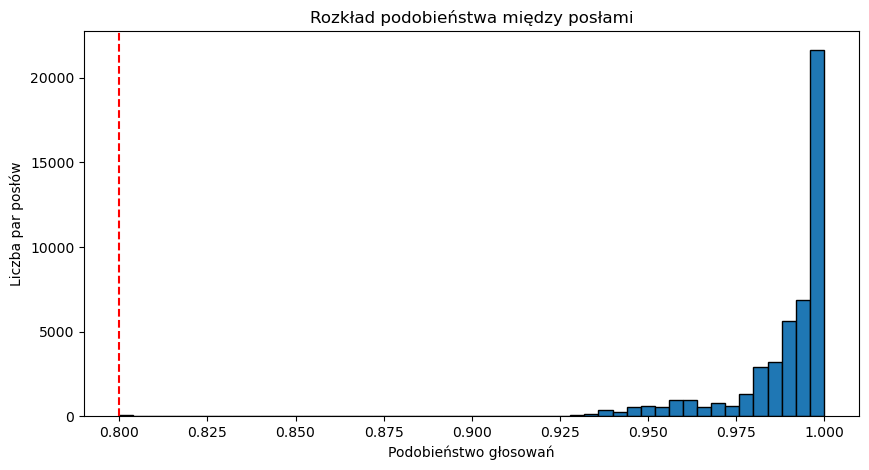

Mediana: 0.994
Średnia: 0.988
% par powyżej 0.5: 100.0%
% par powyżej 0.7: 100.0%


In [35]:
import matplotlib.pyplot as plt

weights = [d["weight"] for a, b, d in G.edges(data=True)]

plt.figure(figsize=(10, 5))
plt.hist(weights, bins=50, edgecolor="black")
plt.xlabel("Podobieństwo głosowań")
plt.ylabel("Liczba par posłów")
plt.title("Rozkład podobieństwa między posłami")
plt.axvline(0.8, color="red", linestyle="--", label="próg 0.8")
plt.savefig("rozklad_wag.png", dpi=150)
plt.show()

# I statystyki
import numpy as np
print(f"Mediana: {np.median(weights):.3f}")
print(f"Średnia: {np.mean(weights):.3f}")
print(f"% par powyżej 0.5: {np.mean(np.array(weights) > 0.5)*100:.1f}%")
print(f"% par powyżej 0.7: {np.mean(np.array(weights) > 0.7)*100:.1f}%")

Dotychczasowy wynik, pokazuje, ze posłowie glosuja bardzo spojnie.
Sprubjmy teraz odfiltorwac glosowania 'nudne', takie w ktorych 85% posłow sie zgadza. W ten sposob usuniemy glosowania "oczywiste", "administracyjne', ktore przechodza pod nosem mediow i maja zgode "wszystckich". Zostana nam glosowania, w ktorych jest wiecej sporu, a wiec i wiecej informacji o tym, kto z kim sie zgadza, a kto nie.

In [43]:
df = pd.read_csv("glosowania_raw.csv")

def kontrowersyjnosc(glosowanie_id):
    g = df[df["glosowanie_id"] == glosowanie_id]["wynik"]
    g = g[g.isin(["YES", "NO"])]
    if len(g) == 0:
        return 0
    mniejszosc = min(g.value_counts())
    return mniejszosc / len(g)

kontrow_scores = {
    g: kontrowersyjnosc(g) 
    for g in df["glosowanie_id"].unique()
}

# Pokaż przykłady z każdego przedziału
df_kontrow = pd.DataFrame([
    {"glosowanie_id": g, "kontrowersyjnosc": s}
    for g, s in kontrow_scores.items()
]).merge(
    df[["glosowanie_id"]].drop_duplicates(),
    on="glosowanie_id"
)

print("Rozkład:")
for prog in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]:
    n = sum(s > prog for s in kontrow_scores.values())
    print(f"  > {prog:.0%} mniejszości: {n} głosowań")

Rozkład:
  > 5% mniejszości: 797 głosowań
  > 10% mniejszości: 751 głosowań
  > 15% mniejszości: 742 głosowań
  > 20% mniejszości: 737 głosowań
  > 25% mniejszości: 734 głosowań
  > 30% mniejszości: 734 głosowań
  > 35% mniejszości: 733 głosowań
  > 40% mniejszości: 718 głosowań


991 unikalnych głosowań
249 z nich jest "jednomyślna" - ponad 85% posłów głosuje tak samo.
Mniejszość głosowań jest jednomyslna


In [44]:
# Sprawdź osobno podobieństwo wewnątrz klubu vs między klubami
within_club = []
between_club = []

for a, b, d in G.edges(data=True):
    klub_a = posel_meta.loc[a, "klub"] if a in posel_meta.index else None
    klub_b = posel_meta.loc[b, "klub"] if b in posel_meta.index else None
    if klub_a and klub_b:
        if klub_a == klub_b:
            within_club.append(d["weight"])
        else:
            between_club.append(d["weight"])

print(f"Wewnątrz klubu — średnia: {np.mean(within_club):.3f}, mediana: {np.median(within_club):.3f}")
print(f"Między klubami — średnia: {np.mean(between_club):.3f}, mediana: {np.median(between_club):.3f}")

Wewnątrz klubu — średnia: 0.995, mediana: 0.997
Między klubami — średnia: 0.974, mediana: 0.982


In [45]:
# Wyświetl przykładowe tematy głosowań
przykladowe = (
    df[["glosowanie_id"]]
    .drop_duplicates()
    .head(20)
)

# Pobierz tematy z API
import requests
BASE = "https://api.sejm.gov.pl/sejm"

for gid in df["glosowanie_id"].unique()[:10]:
    sitting, voting = gid.split("_")
    r = requests.get(f"{BASE}/term10/votings/{sitting}/{voting}")
    data = r.json()
    print(f"{gid}: {data.get('title', 'brak')[:80]}")

20_1: 20. posiedzenie Sejmu Rzeczypospolitej Polskiej w dniach 16, 17 i 18 październik
20_2: 20. posiedzenie Sejmu Rzeczypospolitej Polskiej w dniach 16, 17 i 18 październik
20_3: 20. posiedzenie Sejmu Rzeczypospolitej Polskiej w dniach 16, 17 i 18 październik
20_4: 20. posiedzenie Sejmu Rzeczypospolitej Polskiej w dniach 16, 17 i 18 październik
20_5: Głosowanie proceduralne
20_6: 20. posiedzenie Sejmu Rzeczypospolitej Polskiej w dniach 16, 17 i 18 październik
20_7: 20. posiedzenie Sejmu Rzeczypospolitej Polskiej w dniach 16, 17 i 18 październik
20_8: Pkt. 4 Sprawozdanie Komisji o rządowym projekcie ustawy o świadczeniu honorowym 
20_9: Pkt. 5 Sprawozdanie Komisji o rządowym projekcie ustawy o zmianie niektórych ust
20_10: Pkt. 2 Sprawozdanie Komisji o rządowym projekcie ustawy o zmianie ustawy o podat


In [46]:
n = len(posłowie)
mozliwe = n * (n-1) / 2
faktyczne = G.number_of_edges()
print(f"Możliwych krawędzi: {mozliwe:.0f}")
print(f"Faktycznych krawędzi: {faktyczne}")
print(f"Brakujących: {mozliwe - faktyczne:.0f}")
print(f"Gęstość grafu: {faktyczne/mozliwe:.3f}")


Możliwych krawędzi: 105570
Faktycznych krawędzi: 48358
Brakujących: 57212
Gęstość grafu: 0.458


Co jest w pliku sejm_network_final.gexf
Węzły (461)
Każdy węzeł to jeden poseł. Ma trzy atrybuty:

id — numer posła z API Sejmu
label — nazwisko
club — klub parlamentarny (PiS, KO, Lewica, PSL-TD, Polska2050-TD, Konfederacja, Kukiz15)

Krawędzie (48 358)
Krawędź między posłem A i posłem B istnieje tylko jeśli głosowali tak samo w co najmniej 80% głosowań spośród tych 734 kontrowersyjnych (gdzie mniejszość miała >30% głosów).
Krawędź ma jeden atrybut:

weight — dokładne podobieństwo, np. 0.994 oznacza że głosowali tak samo w 99.4% przypadków

Brak krawędzi między dwoma posłami oznacza że głosowali różnie w ponad 20% głosowań.

Czego NIE ma w tych danych

Nie ma treści głosowań ani nazw ustaw
Nie ma dat — wszystkie głosowania są zagregowane w jedną wartość podobieństwa
Nie ma posłów którzy opuścili zbyt wiele głosowań (filtr both.sum() < 10)


Jak są podzielone krawędzie
Spodziewaj się trzech grup krawędzi:
Grupa 1 — wewnątrz koalicji (~20 000 krawędzi)
Pary KO–Lewica, KO–PSL-TD, KO–Polska2050-TD itp. Waga ~0.85-0.95 — głosują razem ale nie zawsze identycznie, bo to różne partie z różnymi priorytetami.
Grupa 2 — wewnątrz opozycji (~8 000 krawędzi)
Pary PiS–Konfederacja. Waga zróżnicowana — Konfederacja czasem głosuje z koalicją przeciwko PiS w sprawach gospodarczych.
Grupa 3 — wewnątrz każdego klubu (~20 000 krawędzi)
Pary posłów z tego samego klubu. Waga ~0.99 — niemal identyczne wzorce głosowań.

Co znajdziesz w Gephi
Na pewno:

Dwa wyraźne klastry — koalicja i opozycja
Wewnątrz koalicji prawdopodobnie podklastry według partii
Konfederacja może być na granicy lub osobnym wyspą

Potencjalnie interesujące:

Posłowie na granicy między klastrami — głosują nielojalnie wobec swojego bloku
Izolowane węzły — posłowie którzy nie pasują do żadnego klastra (Kukiz15 ma tylko 2-3 posłów)
Różna gęstość wewnątrz klastrów — PiS prawdopodobnie bardziej spójny niż koalicja


Pytanie badawcze które możesz postawić
Masz teraz dane żeby odpowiedzieć na kilka pytań:
Proste (na zaliczenie): Czy struktura sieci podobieństwa głosowań odzwierciedla podział na koalicję i opozycję w X kadencji Sejmu RP?
Ciekawsze: Które partie wewnątrz koalicji są najbardziej spójne, a które głosują bardziej niezależnie? Czy Konfederacja głosuje bliżej opozycji czy jest osobnym bytem?